# 04 — Corrected experiment overview

Notebooks 01–03 now use this same experiment. This overview includes their graphics and a compact score table. Run 01–03 first to regenerate graphics. Training remains in the explicit cell of notebook 02.

In [1]:
from pathlib import Path
import sys, json, os
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'experiments/isolated_arsenal.py').exists())
sys.path.insert(0,str(ROOT))
os.environ.setdefault('MPLCONFIGDIR',str(ROOT/'work/matplotlib'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, joblib
from IPython.display import display, Markdown, Image
from experiments import train
from experiments.isolated_arsenal import OUTPUT
RUN=OUTPUT
REVIEW=ROOT/'results/arsenal_isolated_review'
(REVIEW/'figures').mkdir(parents=True,exist_ok=True)
record=json.loads((RUN/'manifest.json').read_text())
for rel,digest in record['artifact_sha256'].items():
    assert train.digest(RUN/rel)==digest,rel
features=record['features']
plt.rcParams.update({'figure.figsize':(11,5),'axes.spines.top':False,'axes.spines.right':False})
def finish(name):
    plt.tight_layout(); plt.savefig(REVIEW/'figures'/f'{name}.png',dpi=110,bbox_inches='tight'); plt.show(); plt.close()
def load(population,split):
    folder=RUN/population/split
    return (pd.read_csv(folder/'X.csv').astype(np.float32),pd.read_csv(folder/'y.csv').target_result.map({'A':0,'D':1,'H':2}).to_numpy(),pd.read_csv(folder/'index.csv'))
def predict(name,x):
    if name.endswith('mlp'):
        return train.predict_checkpoint(RUN/'models'/f'{name}_best.pt',x).to_numpy()
    return joblib.load(RUN/'models'/f'{name}.joblib').predict_proba(x)
metrics=pd.read_csv(RUN/'evaluation/metrics.csv')
names=metrics.model.drop_duplicates().tolist()
# Source duplicate is a deterministic replication, excluded from model selection.
candidates=[n for n in names if n!='league_frozen_source_mlp']
validation=metrics.query("split=='validation'").set_index('model').loc[candidates]
selected=validation.log_loss.idxmin()


In [2]:
display(pd.DataFrame(record['rows']));display(metrics);display(pd.read_csv(RUN/'models/training_summary.csv'))

,league,arsenal
train,7142,815
validation,654,74
test,656,75


,model,split,population,log_loss,brier_multiclass,accuracy,n
0,arsenal_mlp,validation,Arsenal,0.864435,0.503668,0.702703,74
1,league_mlp,validation,Arsenal,0.797180,0.453334,0.675676,74
2,full_finetune_mlp,validation,Arsenal,0.796803,0.453112,0.689189,74
3,league_frozen_source_mlp,validation,Arsenal,0.797180,0.453334,0.675676,74
4,head_finetune_mlp,validation,Arsenal,0.797128,0.453307,0.675676,74
5,league_random_forest,validation,Arsenal,0.828401,0.471868,0.702703,74
6,league_dummy,validation,Arsenal,1.040882,0.628818,0.472973,74
7,arsenal_mlp,test,Arsenal,0.959723,0.569044,0.600000,75
8,league_mlp,test,Arsenal,0.908240,0.533728,0.613333,75
9,full_finetune_mlp,test,Arsenal,0.908132,0.533687,0.600000,75


,model,best_epoch,epochs_run,validation_log_loss,training_rows,checkpoint_sha256,training_population,validation_population
0,arsenal_mlp,100,100,0.864435,815,66a872e6c2b7e900069cf1e1c178b02f47494040c1f9a1...,arsenal,arsenal
1,league_mlp,99,100,0.975268,7142,103ad2f65ba73a201cc5dfe0f562310f18120450522d9d...,league,league
2,full_finetune_mlp,2,21,0.796803,815,c2a91cef3b525bb3ed0be94ba3250ad4f80c34da20500b...,arsenal,arsenal
3,league_frozen_source_mlp,99,100,0.975268,7142,f88358c991706acc5a6c81e51d9b9d7b3322256583a214...,league,league
4,head_finetune_mlp,1,20,0.797128,815,18cb0477189d6c4d6f1138509a5fdd52dce13b3db0a65e...,arsenal,arsenal


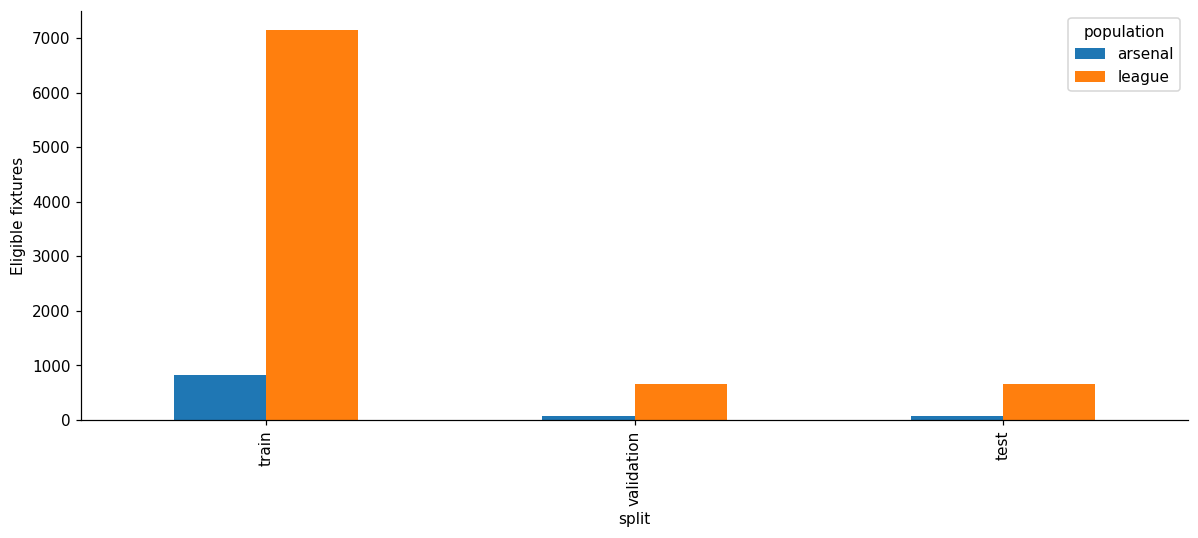

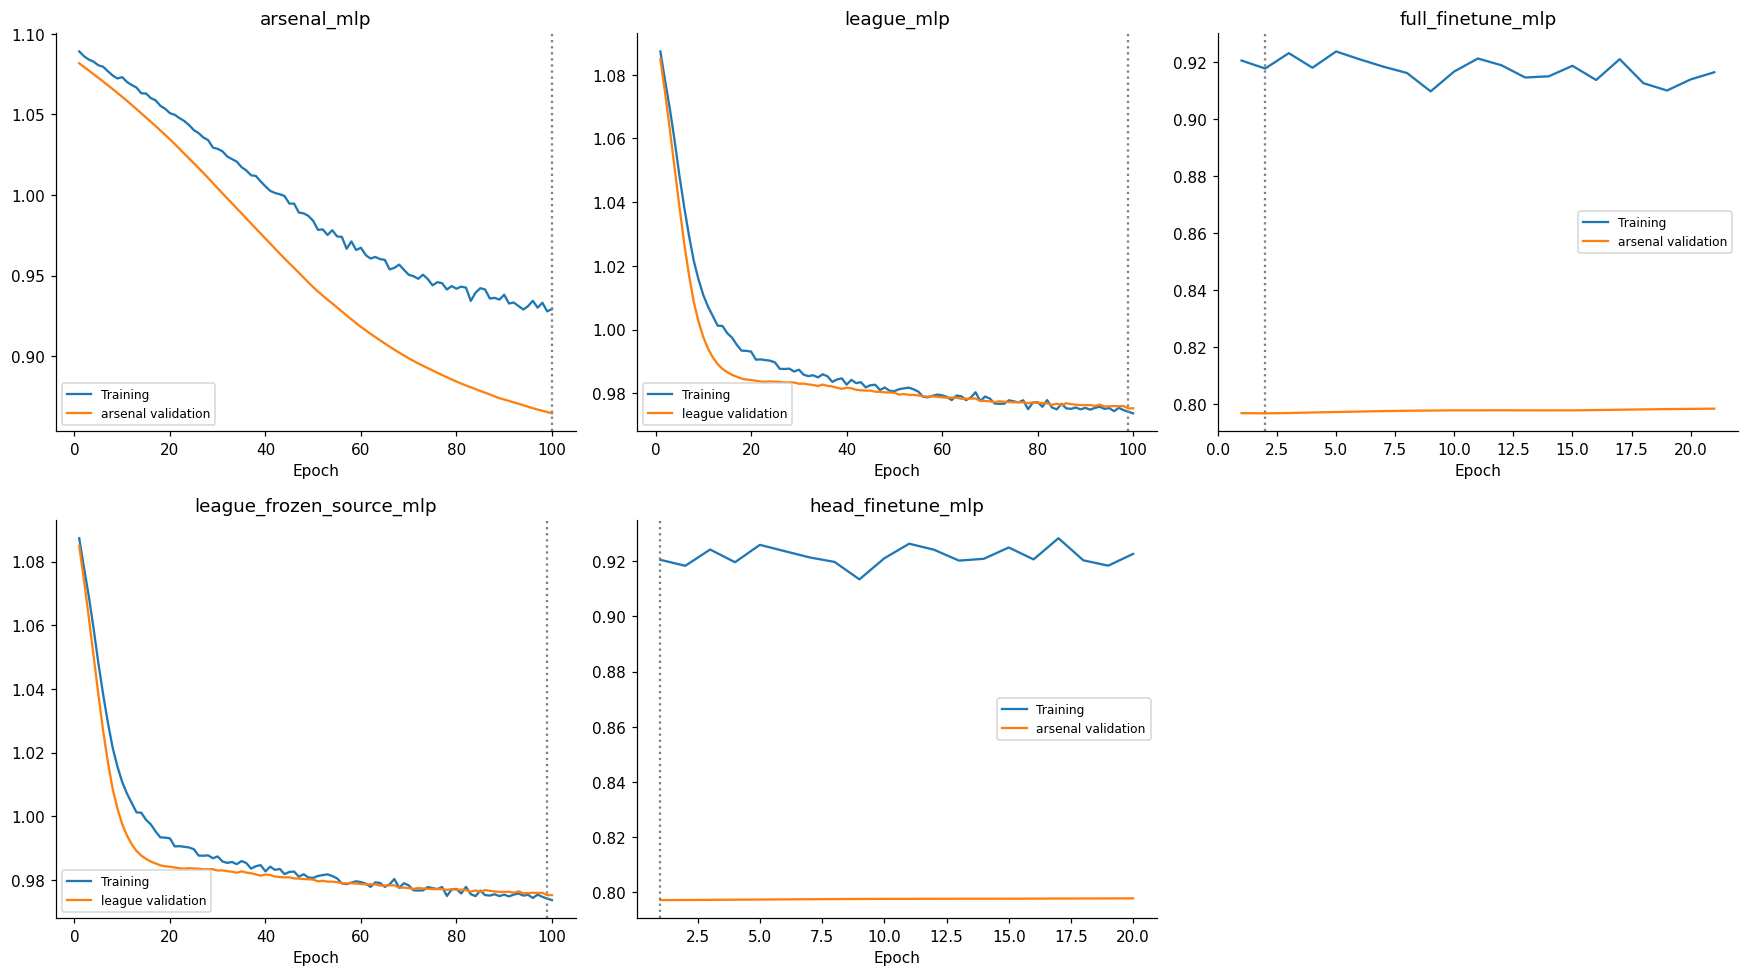

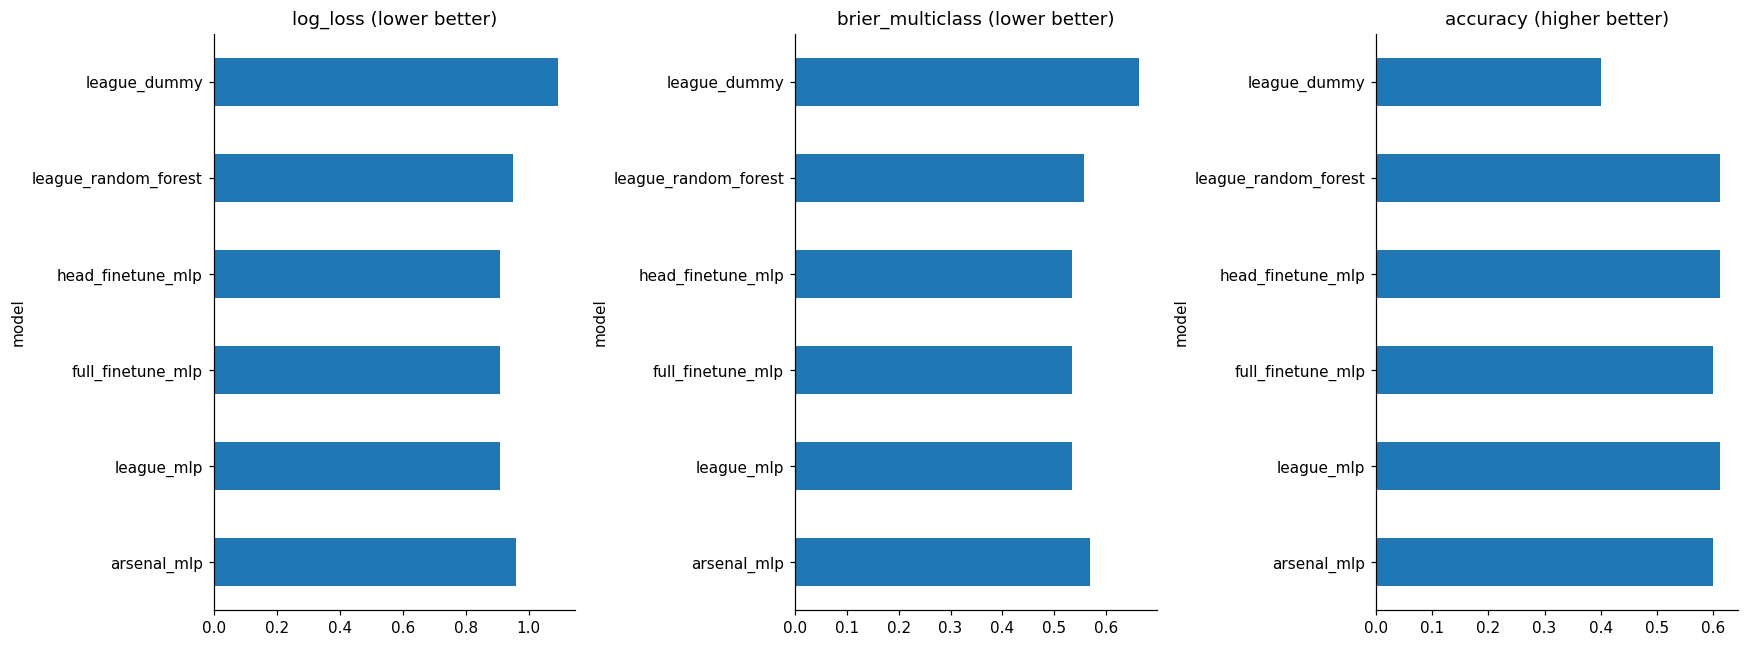

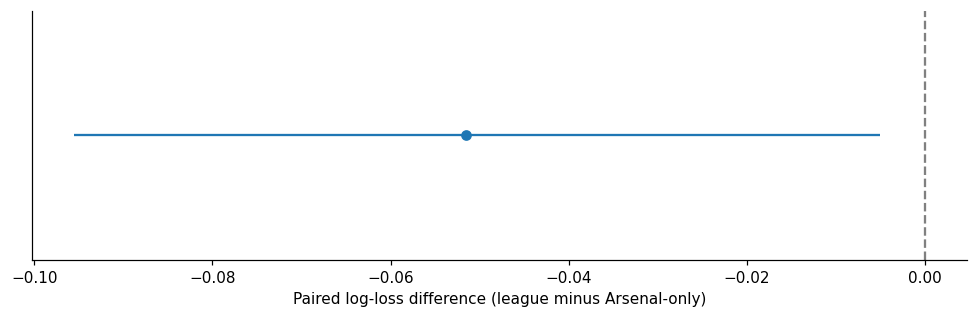

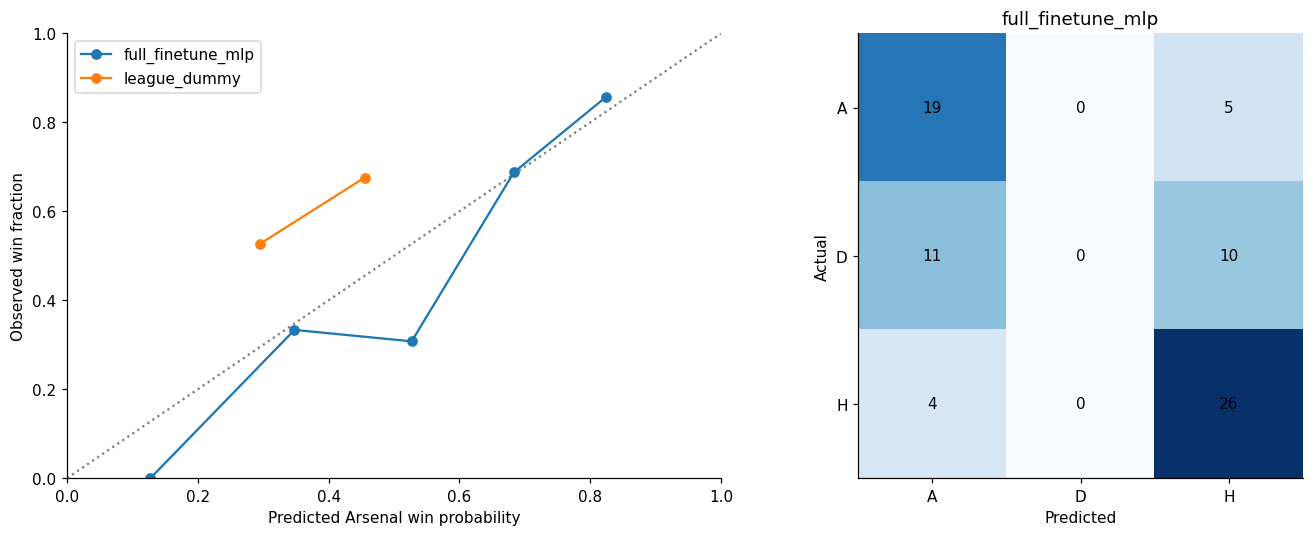

In [3]:
for name in ['07_corrected_splits','11_learning_curves','12_test_metrics','13_paired_uncertainty','14_calibration_confusion']:
    path=REVIEW/'figures'/f'{name}.png'
    assert path.exists(), 'Run notebooks 01–03 first'
    display(Image(filename=str(path)))

Source training excludes Arsenal before feature generation and source checkpoint selection excludes Arsenal. Source and target historical feature distributions differ by design. Every requested model arm has completed; head-only hidden weights are checked in 02. These are exploratory, single-seed results on an already inspected test period.